> **Historical comparison:** this notebook is an executed broad T7 snapshot and is retained for auditability. It is not the canonical current result. The refreshed October 2 Trump audit, event-cluster intervals, snapshot comparison, and corrected interpretation are in [mention-markets-validation-consolidated.ipynb](mention-markets-validation-consolidated.ipynb) and [mention-markets-validation-report.md](mention-markets-validation-report.md).

# Trump mention-market long-shot bias validation

This reproducible notebook re-runs the project’s VWAP and calibration pipeline on the current T7 snapshot and tests the claim that:

- contracts priced near 30% resolve **YES less often** than 30%; and
- contracts priced at 70% or more resolve **YES more often** than their price implies.

The primary estimate uses the 2-hour VWAP before the final recorded trade, with sensitivity checks at 1 hour, 30 minutes, and 10 minutes. The notebook also uses event-cluster bootstrap intervals because many contracts belong to the same speech and are not independent observations.

Sources: the repository code in `src/`, the T7 drive at `/Volumes/T7/mention-markets`, and the two essays [Political Mention Market Calibration](https://lfpmb.com/articles/political-mention-market-calibration) and [Cross-Category Calibration Analysis](https://lfpmb.com/articles/cross-category-calibration-analysis).

In [1]:
from pathlib import Path
import sys
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Run from the repository root, or adjust this path when opening the notebook elsewhere.
REPO = Path.cwd()
if not (REPO / "src").exists():
    REPO = Path("/Users/lfpmb/Documents/mention-analysis")
sys.path.insert(0, str(REPO))

from src.data_loading import load_markets, load_mention_markets
from src.metrics import strategy_profits

plt.style.use("seaborn-v0_8-whitegrid")
OUTPUT = REPO / "output" / "trump-longshot-bias-validation_files"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 1. Data inventory and provenance

This notebook is retained as a reproducible broad-snapshot comparison. The loader ignores macOS `._*.parquet` sidecars and computes VWAPs relative to each market's final recorded trade. The snapshot's counts are historical outputs; use the manifest-backed October 2 audit for the current Trump question.

In [2]:
MARKET_ROOT = Path("/Volumes/T7/mention-markets")
market_files = sorted(p for p in (MARKET_ROOT / "markets").glob("*.parquet") if not p.name.startswith("._"))
trade_files = sorted(p for p in (MARKET_ROOT / "trades").glob("*.parquet") if not p.name.startswith("._"))

markets_raw = load_markets()
vwap_all = load_mention_markets()

inventory = pd.DataFrame({
    "measure": ["market parquet files", "trade parquet files", "raw market rows", "raw resolved rows", "VWAP rows", "VWAP rows with 2h value", "raw series values"],
    "value": [len(market_files), len(trade_files), len(markets_raw), int(markets_raw.result.isin(["yes", "no"]).sum()), len(vwap_all), int(vwap_all.vwap_2h.notna().sum()), int(markets_raw.series.nunique())],
})
display(inventory)
print("Raw market date range:", markets_raw.close_time.min(), "to", markets_raw.close_time.max())
print("VWAP date range:", vwap_all.close_time.min(), "to", vwap_all.close_time.max())


,measure,value
0,market parquet files,141
1,trade parquet files,141
2,raw market rows,38450
3,raw resolved rows,36214
4,VWAP rows,21975
5,VWAP rows with 2h value,20979
6,raw series values,143


Raw market date range: 2025-01-30 12:55:29.003392-08:00 to 2026-08-08 07:00:00-07:00
VWAP date range: 2025-01-30 12:55:29.003392-08:00 to 2026-07-05 12:09:59-07:00


## 2. Canonicalize the Trump universe

The broad metadata has three series values for Trump contracts: `KXTRUMPMENTION`, `A`, and `B`. The ticker prefix is the stable identifier, so this historical comparison selects `ticker.startswith("KXTRUMPMENTION")`. The consolidated current audit uses the explicit refreshed universe and should be treated as the primary estimate.

In [3]:
trump_meta = markets_raw.loc[
    markets_raw.ticker.astype(str).str.startswith("KXTRUMPMENTION")
    & markets_raw.result.isin(["yes", "no"])
].copy()

trump = vwap_all.merge(
    markets_raw[["ticker", "event_ticker", "title", "status", "series", "result", "close_time"]],
    on="ticker",
    how="inner",
    suffixes=("", "_meta"),
)
trump = trump.loc[trump.ticker.astype(str).str.startswith("KXTRUMPMENTION")].copy()
trump["actual_yes"] = trump["result"].eq("yes")
trump["event_ticker"] = trump["event_ticker"].fillna(trump["ticker"].str.rsplit("-", n=1).str[0])
trump["p_2h"] = trump["vwap_2h"]

series_audit = (
    trump_meta.groupby("series", dropna=False)
    .agg(raw_markets=("ticker", "size"), resolved=("result", lambda s: s.isin(["yes", "no"]).sum()))
    .reset_index()
)
valid_trump = trump.dropna(subset=["p_2h"]).copy()
summary = pd.DataFrame({
    "measure": ["raw Trump rows", "raw resolved Trump rows", "resolved Trump rows with 2h VWAP", "distinct events", "YES rate"],
    "value": [len(markets_raw.loc[markets_raw.ticker.astype(str).str.startswith("KXTRUMPMENTION")]), len(trump_meta), len(valid_trump), valid_trump.event_ticker.nunique(), valid_trump.actual_yes.mean()],
})
display(series_audit)
display(summary)


,series,raw_markets,resolved
0,A,1267,1267
1,B,460,460
2,KXTRUMPMENTION,4814,4814


,measure,value
0,raw Trump rows,6745.000000
1,raw resolved Trump rows,6541.000000
2,resolved Trump rows with 2h VWAP,6352.000000
3,distinct events,260.000000
4,YES rate,0.436241


## 3. Data-quality checks

These checks establish the analysis grain and identify missingness or timestamp anomalies. `close_time - last_trade_time` is a trading-stop diagnostic in this loader; it is not a settlement payout lag. The refreshed audit reports `settlement_ts` separately.

In [4]:
horizons = ["7d", "3d", "1d", "6h", "2h", "1h", "30m", "10m"]
quality_rows = []
for h in horizons:
    s = trump[f"vwap_{h}"]
    quality_rows.append({"horizon": h, "rows": len(trump), "non_null": int(s.notna().sum()), "missing_pct": float(s.isna().mean()), "min": s.min(), "max": s.max()})
quality = pd.DataFrame(quality_rows)
quality["missing_pct"] = (quality["missing_pct"] * 100).round(2)
display(quality)

trump["close_time"] = pd.to_datetime(trump["close_time"], utc=True)
trump["last_trade_time"] = pd.to_datetime(trump["last_trade_time"], utc=True)
trump["settlement_lag_min"] = (trump["close_time"] - trump["last_trade_time"]).dt.total_seconds() / 60
lag = trump["settlement_lag_min"].dropna()
lag_pos = lag.loc[lag >= 0]
quality_summary = pd.DataFrame({
    "check": ["duplicate tickers", "negative close-minus-last-trade lag", "median positive lag (min)", "positive lag > 1h", "positive lag > 4h"],
    "value": [int(trump.ticker.duplicated().sum()), int((lag < 0).sum()), round(lag_pos.median(), 1), round((lag_pos > 60).mean() * 100, 1), round((lag_pos > 240).mean() * 100, 1)],
})
display(quality_summary)

# The cross-category essay uses the all-market population, so keep a separate
# all-market lag series for that comparison below.
vwap_all["close_time"] = pd.to_datetime(vwap_all["close_time"], utc=True)
vwap_all["last_trade_time"] = pd.to_datetime(vwap_all["last_trade_time"], utc=True)
lag_all = (vwap_all["close_time"] - vwap_all["last_trade_time"]).dt.total_seconds() / 60
lag_all_pos = lag_all.dropna().loc[lambda s: s >= 0]


,horizon,rows,non_null,missing_pct,min,max
0,7d,6539,184,97.19,5.000000,92.796753
1,3d,6539,601,90.81,1.235294,95.571429
2,1d,6539,1788,72.66,1.020954,98.684943
3,6h,6539,5407,17.31,1.000000,99.000000
4,2h,6539,6352,2.86,1.000000,99.000000
5,1h,6539,6473,1.01,1.002317,98.898069
6,30m,6539,6524,0.23,1.002276,98.898069
7,10m,6539,6532,0.11,1.002235,98.898069


,check,value
0,duplicate tickers,0.0
1,negative close-minus-last-trade lag,163.0
2,median positive lag (min),33.1
3,positive lag > 1h,36.5
4,positive lag > 4h,17.5


## 4. Calibration with mean implied probability

The table reports both the number of contracts and the **mean VWAP inside each bin**, which avoids treating a skewed 20–30% bin as if every contract were exactly 25%. The calibration error is `actual YES rate − mean implied probability`, in percentage points. The fixed midpoint is a display label, not the error reference.

In [5]:
def calibration_table(data, p_col="p_2h", bin_size=10):
    d = data.dropna(subset=[p_col]).copy()
    edges = np.arange(0, 100 + bin_size, bin_size)
    labels = [f"{int(lo)}–{int(hi)}%" for lo, hi in zip(edges[:-1], edges[1:])]
    d["price_band"] = pd.cut(d[p_col], bins=edges, labels=labels, include_lowest=True, right=True)
    out = (
        d.groupby("price_band", observed=False)
        .agg(
            contracts=("actual_yes", "size"),
            events=("event_ticker", "nunique"),
            mean_implied_pct=(p_col, lambda s: s.mean()),
            actual_yes_pct=("actual_yes", lambda s: 100 * s.mean()),
        )
        .reset_index()
    )
    out["error_pp"] = out["actual_yes_pct"] - out["mean_implied_pct"]
    return out

cal_2h = calibration_table(valid_trump)
display(cal_2h.round({"mean_implied_pct": 2, "actual_yes_pct": 2, "error_pp": 2}))


,price_band,contracts,events,mean_implied_pct,actual_yes_pct,error_pp
0,0–10%,782,192,5.51,1.15,-4.36
1,10–20%,816,209,14.99,4.29,-10.71
2,20–30%,731,211,24.91,12.59,-12.32
3,30–40%,592,191,34.88,22.97,-11.90
4,40–50%,516,178,45.03,35.27,-9.75
5,50–60%,557,179,55.24,51.17,-4.07
6,60–70%,640,195,65.07,70.94,5.87
7,70–80%,600,194,75.20,86.00,10.80
8,80–90%,693,193,84.99,92.64,7.65
9,90–100%,425,149,93.43,98.82,5.39


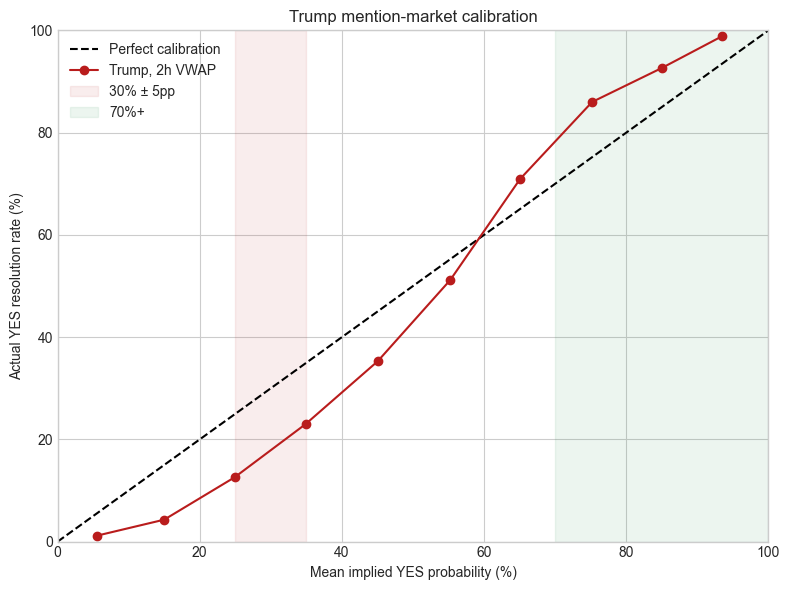

In [6]:
# Calibration curve using the mean implied price in each 10-cent bin.
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([0, 100], [0, 100], "--", color="black", label="Perfect calibration")
ax.plot(cal_2h.mean_implied_pct, cal_2h.actual_yes_pct, "o-", color="#b91c1c", label="Trump, 2h VWAP")
ax.axvspan(25, 35, color="#b91c1c", alpha=0.08, label="30% ± 5pp")
ax.axvspan(70, 100, color="#15803d", alpha=0.08, label="70%+")
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel="Mean implied YES probability (%)", ylabel="Actual YES resolution rate (%)")
ax.set_title("Trump mention-market calibration")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(OUTPUT / "trump-calibration-2h.png", dpi=160)
plt.show()


## 5. Direct tests of the 30% and 70% claims

The primary bands are 25–35% (the “around 30%” claim), 70–80% (a local test of the 70% claim), and 70%+ (the broad high-probability claim). Event-cluster bootstrap intervals resample speeches/events rather than individual contracts.

In [7]:
def band_summary(data, label, lo, hi):
    d = data.loc[(data.p_2h >= lo) & (data.p_2h < hi)].copy()
    if d.empty:
        return {"band": label, "contracts": 0, "events": 0, "mean_implied_pct": np.nan, "actual_yes_pct": np.nan, "error_pp": np.nan}
    return {
        "band": label,
        "contracts": len(d),
        "events": d.event_ticker.nunique(),
        "mean_implied_pct": d.p_2h.mean(),
        "actual_yes_pct": 100 * d.actual_yes.mean(),
        "error_pp": 100 * (d.actual_yes.mean() - d.p_2h.mean() / 100),
    }

bands = [
    ("30% ± 5pp", 25, 35),
    ("70–80%", 70, 80),
    ("70%+", 70, 100.0001),
]
direct = pd.DataFrame([band_summary(valid_trump, *b) for b in bands])
display(direct.round({"mean_implied_pct": 2, "actual_yes_pct": 2, "error_pp": 2}))


,band,contracts,events,mean_implied_pct,actual_yes_pct,error_pp
0,30% ± 5pp,676,196,29.71,17.01,-12.70
1,70–80%,600,195,75.18,86.00,10.82
2,70%+,1719,232,83.65,91.86,8.20


In [8]:
def cluster_bootstrap_error(data, lo, hi, p_col="p_2h", reps=5000, seed=20261002):
    d = data.loc[(data[p_col] >= lo) & (data[p_col] < hi)].dropna(subset=[p_col, "event_ticker"]).copy()
    grouped = d.groupby("event_ticker", observed=True).agg(
        n=("actual_yes", "size"), wins=("actual_yes", "sum"), p_sum=(p_col, "sum")
    )
    if len(grouped) < 2:
        return np.array([np.nan, np.nan, np.nan])
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(grouped), size=(reps, len(grouped)))
    n = grouped.n.to_numpy()[idx].sum(axis=1)
    wins = grouped.wins.to_numpy()[idx].sum(axis=1)
    p_sum = grouped.p_sum.to_numpy()[idx].sum(axis=1)
    errors = 100 * (wins / n - p_sum / n / 100)
    return np.percentile(errors, [2.5, 50, 97.5])

ci_rows = []
for label, lo, hi in bands:
    row = band_summary(valid_trump, label, lo, hi)
    lo_ci, med_ci, hi_ci = cluster_bootstrap_error(valid_trump, lo, hi)
    row.update({"cluster_boot_low_pp": lo_ci, "cluster_boot_median_pp": med_ci, "cluster_boot_high_pp": hi_ci})
    ci_rows.append(row)
ci_table = pd.DataFrame(ci_rows)
display(ci_table.round({c: 2 for c in ci_table.columns if c.endswith("pp") or "pct" in c}))


,band,contracts,events,mean_implied_pct,actual_yes_pct,error_pp,cluster_boot_low_pp,cluster_boot_median_pp,cluster_boot_high_pp
0,30% ± 5pp,676,196,29.71,17.01,-12.70,-16.29,-12.75,-8.97
1,70–80%,600,195,75.18,86.00,10.82,7.20,10.87,14.31
2,70%+,1719,232,83.65,91.86,8.20,6.20,8.26,10.11


Interpretation: this broad snapshot is useful historical evidence, but it should not be described as the current Trump result. The refreshed October 2 audit narrows the conclusion: the 2-hour 25–35% band is below its mean implied probability, while the 70%+ band is approximately calibrated within the event-cluster interval.

## 6. Recency and horizon sensitivity

A full-history result can overstate a live edge if the market is becoming more efficient. These broad-snapshot tables are sensitivity diagnostics. The manifest-backed refreshed audit in the consolidated notebook is the source for the current horizon and recency estimates.

In [9]:
periods = {
    "all history": valid_trump,
    "2026": valid_trump.loc[valid_trump.close_time.dt.year == 2026],
    "last 180 days": valid_trump.loc[valid_trump.close_time >= valid_trump.close_time.max() - pd.Timedelta(days=180)],
    "last 90 days": valid_trump.loc[valid_trump.close_time >= valid_trump.close_time.max() - pd.Timedelta(days=90)],
}
rows = []
for period, d in periods.items():
    for label, lo, hi in bands:
        row = band_summary(d, label, lo, hi)
        row["period"] = period
        rows.append(row)
recency = pd.DataFrame(rows)[["period", "band", "contracts", "events", "mean_implied_pct", "actual_yes_pct", "error_pp"]]
display(recency.round({"mean_implied_pct": 2, "actual_yes_pct": 2, "error_pp": 2}))


,period,band,contracts,events,mean_implied_pct,actual_yes_pct,error_pp
0,all history,30% ± 5pp,676,196,29.71,17.01,-12.70
1,all history,70–80%,600,195,75.18,86.00,10.82
2,all history,70%+,1719,232,83.65,91.86,8.20
3,2026,30% ± 5pp,362,103,29.80,22.93,-6.87
4,2026,70–80%,311,102,75.28,78.78,3.50
5,2026,70%+,824,114,83.10,86.89,3.80
6,last 180 days,30% ± 5pp,361,102,29.80,22.99,-6.81
7,last 180 days,70–80%,308,101,75.29,78.90,3.61
8,last 180 days,70%+,810,113,83.08,86.79,3.71
9,last 90 days,30% ± 5pp,191,49,29.86,21.99,-7.87


In [10]:
horizon_rows = []
for h in ["6h", "2h", "1h", "30m", "10m"]:
    d = valid_trump.dropna(subset=[f"vwap_{h}"]).copy()
    d["p_2h"] = d[f"vwap_{h}"]
    for label, lo, hi in [("30% ± 5pp", 25, 35), ("70–80%", 70, 80), ("70%+", 70, 100.0001)]:
        row = band_summary(d, label, lo, hi)
        row["horizon"] = h
        horizon_rows.append(row)
horizon_table = pd.DataFrame(horizon_rows)[["horizon", "band", "contracts", "mean_implied_pct", "actual_yes_pct", "error_pp"]]
display(horizon_table.round({"mean_implied_pct": 2, "actual_yes_pct": 2, "error_pp": 2}))


,horizon,band,contracts,mean_implied_pct,actual_yes_pct,error_pp
0,6h,30% ± 5pp,601,30.05,19.63,-10.41
1,6h,70–80%,589,74.78,78.78,3.99
2,6h,70%+,1375,82.11,86.62,4.51
3,2h,30% ± 5pp,676,29.71,17.01,-12.70
4,2h,70–80%,600,75.18,86.00,10.82
5,2h,70%+,1719,83.65,91.86,8.20
6,1h,30% ± 5pp,584,29.71,10.96,-18.75
7,1h,70–80%,620,75.03,89.68,14.65
8,1h,70%+,1920,84.25,94.84,10.59
9,30m,30% ± 5pp,560,29.57,5.54,-24.04


The broad snapshot's horizon signs are descriptive and use different available-contract sets. They do not establish monotonic improvement or a live trading signal. The consolidated notebook reports event counts and cluster intervals for the refreshed audit.

## 7. Fee-adjusted threshold benchmark

This reproduces the repository’s `strategy_profits` calculation for one contract per market at the VWAP price, including the project’s taker-fee function. It is a benchmark, not an executable fill simulation: it does not model queue position, slippage, or correlated drawdowns.

In [11]:
yes_strategy = strategy_profits(
    valid_trump, price_col="p_2h", actual_col="actual_yes",
    thresholds=[20, 30, 40, 50, 60, 70, 80, 90], side="yes"
)
no_strategy = strategy_profits(
    valid_trump, price_col="p_2h", actual_col="actual_yes",
    thresholds=[20, 30, 40, 50, 60, 70, 80, 90], side="no"
)

display(yes_strategy[["threshold", "trades", "net_pnl_per_trade", "net_return", "hit_rate"]].round(4))
display(no_strategy[["threshold", "trades", "net_pnl_per_trade", "net_return", "hit_rate"]].round(4))


,threshold,trades,net_pnl_per_trade,net_return,hit_rate
0,20,4754,-2.9670,-0.0492,0.5736
1,30,4023,-0.9035,-0.0136,0.6550
2,40,3431,1.3398,0.0187,0.7284
3,50,2915,3.6575,0.0482,0.7949
4,60,2358,5.9552,0.0742,0.8617
5,70,1718,6.7319,0.0791,0.9185
6,80,1118,5.6212,0.0629,0.9499
7,90,425,4.3915,0.0465,0.9882


,threshold,trades,net_pnl_per_trade,net_return,hit_rate
0,20,1597,6.4519,0.0711,0.9724
1,30,2328,7.6633,0.0886,0.9416
2,40,2921,8.1245,0.0984,0.9069
3,50,3435,8.0747,0.1026,0.8681
4,60,3994,7.2321,0.0974,0.8150
5,70,4633,5.1544,0.0746,0.7427
6,80,5233,3.0937,0.0481,0.6736
7,90,5926,1.6703,0.0285,0.6033


## 8. Validate the two essays against this historical snapshot

The essays' original counts and exact-series filter are historical and under-inclusive when rerun on current T7 metadata. This notebook preserves the comparison; the consolidated notebook is the canonical claim ledger.

In [12]:
validation = pd.DataFrame([
    {
        "claim": "Political sample = 7,320 contracts; Trump = 3,401",
        "current_reproduction": f"{int((vwap_all.series.isin(['KXTRUMPMENTION'])).sum())} rows for exact series; {len(valid_trump)} valid Trump 2h rows when ticker-prefix canonicalized",
        "verdict": "Outdated and under-inclusive; current Trump contracts are split across KXTRUMPMENTION/A/B",
    },
    {
        "claim": "Cross-category valid sample = 18,948",
        "current_reproduction": f"{int(vwap_all.vwap_2h.notna().sum())} valid 2h rows across {int(vwap_all.series.nunique())} series values",
        "verdict": "Historical snapshot; cannot be presented as current",
    },
    {
        "claim": "Settlement lag median = 71 minutes; >1h = 53.2%",
        "current_reproduction": f"{lag_all_pos.median():.1f} minutes; {(lag_all_pos > 60).mean():.1%} >1h; {(lag_all_pos > 240).mean():.1%} >4h",
        "verdict": "Historical and changed in the current snapshot",
    },
    {
        "claim": "Political markets show long-shot bias",
        "current_reproduction": f"Full canonical Trump sample: 30%±5pp error {direct.loc[direct.band.eq('30% ± 5pp'),'error_pp'].iloc[0]:.1f}pp; 70%+ error {direct.loc[direct.band.eq('70%+'),'error_pp'].iloc[0]:.1f}pp",
        "verdict": "Supported descriptively; recency and event dependence reduce certainty about a persistent live edge",
    },
    {
        "claim": "Strategy returns are evidence of tradable alpha",
        "current_reproduction": "Positive VWAP benchmark PnL survives the project fee formula",
        "verdict": "In-sample benchmark only; needs time-split and execution-aware validation",
    },
])
display(validation)


,claim,current_reproduction,verdict
0,"Political sample = 7,320 contracts; Trump = 3,401",4812 rows for exact series; 6352 valid Trump 2...,Outdated and under-inclusive; current Trump co...
1,"Cross-category valid sample = 18,948",20979 valid 2h rows across 128 series values,Historical snapshot; cannot be presented as cu...
2,Settlement lag median = 71 minutes; >1h = 53.2%,58.0 minutes; 49.3% >1h; 21.2% >4h,Historical and changed in the current snapshot
3,Political markets show long-shot bias,Full canonical Trump sample: 30%±5pp error -12...,Supported descriptively; recency and event dep...
4,Strategy returns are evidence of tradable alpha,Positive VWAP benchmark PnL survives the proje...,In-sample benchmark only; needs time-split and...


## 9. Corrections required for a defensible update

1. **Use a canonical market universe.** Select Trump contracts by ticker prefix or a maintained event-series mapping, and document inclusion of `A` and `B`.
2. **Report mean implied probability in each calibration bin.** Keep bucket midpoints only as labels.
3. **Separate descriptive calibration from trading performance.** Use a chronological event-level holdout and model executable fills.
4. **Define the target horizon before looking at outcomes.** The 2-hour result is the primary current benchmark; near-event horizons can have selection and liquidity effects.
5. **Separate timestamps.** Use `last_trade_time` for a trading-stop anchor and `settlement_ts` for payout timing.
6. **Cluster uncertainty by event.** Contracts from one speech are correlated.


## Conclusion

This notebook provides an auditable historical broad-snapshot comparison. It supports rechecking the data-loading and calibration code, but it does not establish a persistent favorite-side effect. In the refreshed Trump audit, the low-probability 25–35% discrepancy remains visible at 2 hours; the 70%+ result is approximately calibrated and its interval includes zero. Treat the older broad-snapshot positive high-side result as snapshot-sensitive evidence, not a current trading rule.